# **Lab 8 - Edge Detection (Task)**

**Name:** Danyal ALhashem  
**ID:** 2240002713

**Objective:** Apply and compare edge detection methods using Python and OpenCV, and investigate how parameter changes affect the detected edges.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# New image of my choice (not one of the images provided with the lab)
imgFile = 'cat.jpg'

img = cv2.imread(imgFile)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)   # reduce noise before differentiation
print('Image size:', img.shape)

Image size: (300, 451, 3)


## **Task 1: Apply Edge Detection Methods**

Sobel, Prewitt and Canny are applied to the selected image, following the reference notebook.

### Sobel Edge Detector

In [2]:
sobelx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
sobel_combined = cv2.magnitude(sobelx, sobely)
sobel_final = np.uint8(np.clip(sobel_combined, 0, 255))   # clip to avoid uint8 wrap-around

### Prewitt Edge Detector

In [3]:
kernel_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64)
kernel_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float64)
prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)
prewitt_combined = cv2.magnitude(prewitt_x, prewitt_y)
prewitt_final = np.uint8(np.clip(prewitt_combined, 0, 255))

### Canny Edge Detector

In [4]:
canny_edges = cv2.Canny(gray, 100, 200)

### Display: Original image and the three edge maps

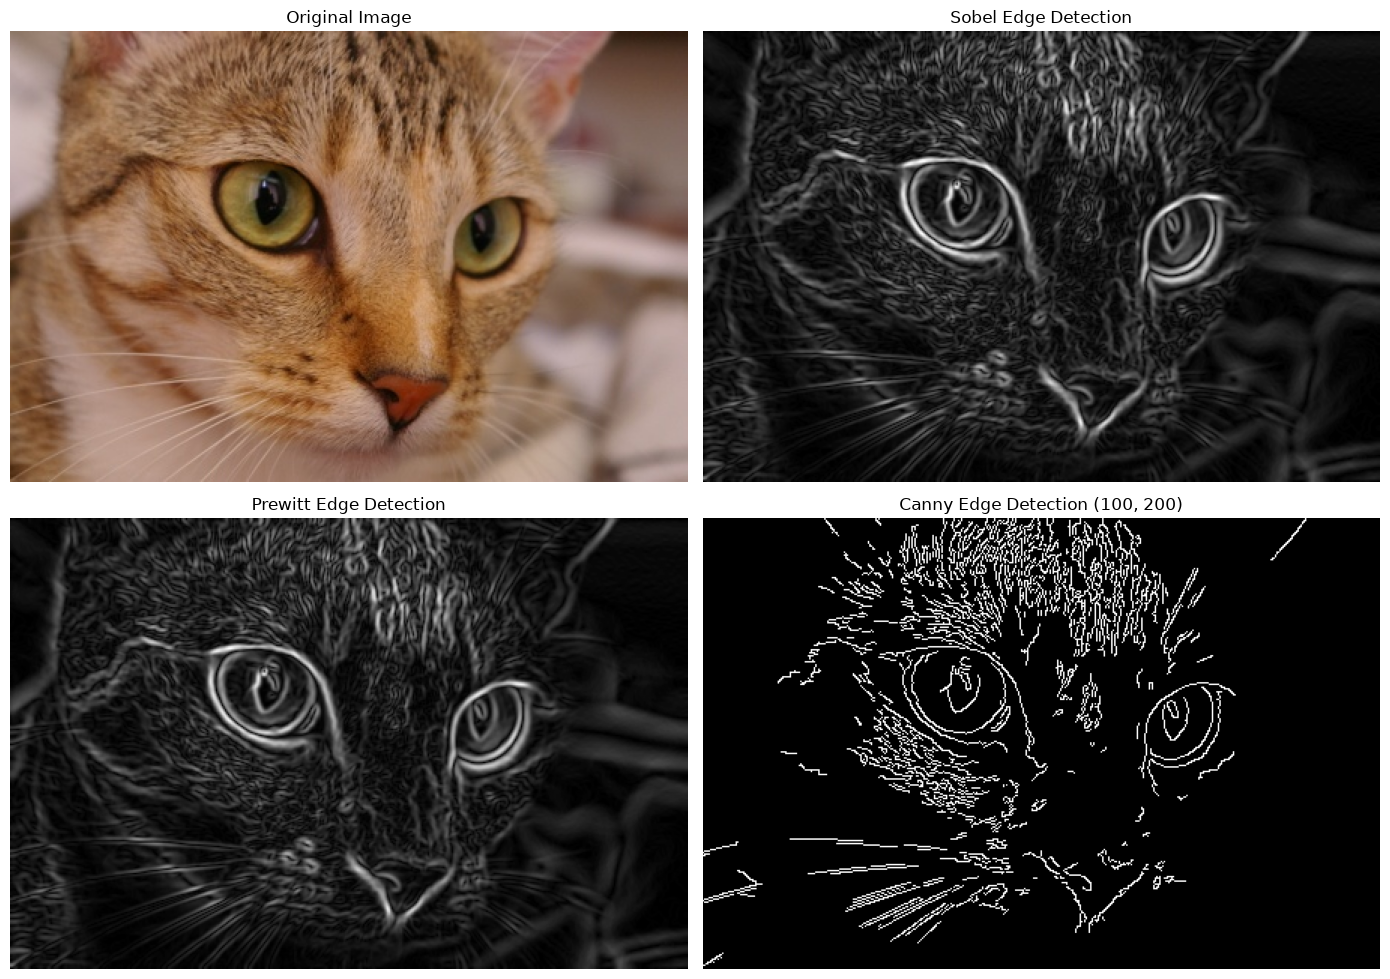

In [5]:
plt.figure(figsize=(14, 10))
plt.subplot(2, 2, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Original Image'), plt.axis('off')
plt.subplot(2, 2, 2), plt.imshow(sobel_final, cmap='gray'), plt.title('Sobel Edge Detection'), plt.axis('off')
plt.subplot(2, 2, 3), plt.imshow(prewitt_final, cmap='gray'), plt.title('Prewitt Edge Detection'), plt.axis('off')
plt.subplot(2, 2, 4), plt.imshow(canny_edges, cmap='gray'), plt.title('Canny Edge Detection (100, 200)'), plt.axis('off')
plt.tight_layout()
plt.show()

**Comparison:**
- **Sobel** gives strong, bright edges around the eyes, the nose and the whiskers. Its kernel weights the center row/column by 2, so it smooths a little while differentiating and is less sensitive to noise.
- **Prewitt** gives a very similar result to Sobel (same 3x3 size) but with equal weights, so the edges are slightly weaker and the fur texture looks a little noisier.
- **Canny** gives a binary map with thin, one-pixel edges thanks to non-maximum suppression and hysteresis thresholding. The eye contours, pupils, nose and whiskers are clear, and the blurred background is almost completely removed. Some fur stripes on the forehead are still detected because they have strong contrast.

## **Task 2: Investigate the Effect of Canny Thresholds**

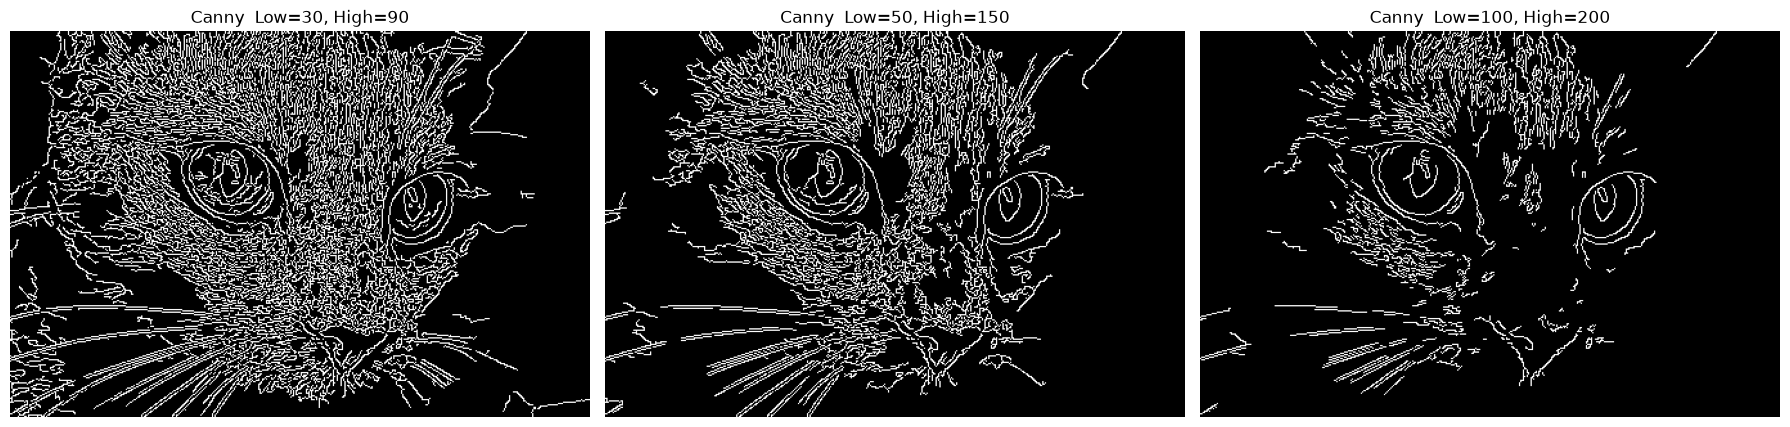

Low= 30, High= 90  ->  edge pixels =  26290  (19.43% of image)
Low= 50, High=150  ->  edge pixels =  17904  (13.23% of image)
Low=100, High=200  ->  edge pixels =   8743  (6.46% of image)


In [6]:
thresholds = [(30, 90), (50, 150), (100, 200)]
results = {}

plt.figure(figsize=(18, 6))
for i, (low, high) in enumerate(thresholds, 1):
    edges = cv2.Canny(gray, low, high)
    results[(low, high)] = edges
    plt.subplot(1, 3, i), plt.imshow(edges, cmap='gray')
    plt.title(f'Canny  Low={low}, High={high}'), plt.axis('off')
plt.tight_layout()
plt.show()

# Count detected edge pixels for each threshold pair
total = gray.size
for (low, high), edges in results.items():
    n = np.count_nonzero(edges)
    print(f'Low={low:3d}, High={high:3d}  ->  edge pixels = {n:6d}  ({100*n/total:.2f}% of image)')

### Explanation

| Thresholds (Low, High) | Edge pixels | % of image |
|---|---|---|
| 30, 90 | 26,290 | 19.43 % |
| 50, 150 | 17,904 | 13.23 % |
| 100, 200 | 8,743 | 6.46 % |

**How the thresholds work in Canny (hysteresis):**
- A pixel whose gradient is **above High** is a *strong edge* and is always kept.
- A pixel **below Low** is rejected.
- A pixel **between Low and High** is a *weak edge*; it is kept only if it is connected to a strong edge.

**Effect on the number of edges:** As the thresholds increase, the number of detected edges decreases. Going from (30, 90) to (100, 200) reduces the edge pixels about three times (19.43 % → 6.46 %), because fewer pixels have a gradient strong enough to pass the thresholds.

**Effect on the visibility of image details:**
- **Low = 30, High = 90:** The most edges and the most detail. Almost every hair of the fur on the face and cheeks is detected, plus some edges in the blurred background. The map is very cluttered and the important shapes (eyes, nose) are harder to see among the texture.
- **Low = 50, High = 150:** A balanced result. The eyes, nose and whiskers are clear, and a lot of the fine fur texture and background edges are removed, although the forehead stripes are still dense.
- **Low = 100, High = 200:** The fewest edges. Only the strongest boundaries remain: the eye contours and pupils, the whiskers, the nose and the main forehead stripes. The map is the cleanest, but weak details such as the outline of the face, the ears and parts of the nose are lost or broken.

**Conclusion:** Low thresholds increase sensitivity (more detail but more texture/noise and false edges), while high thresholds increase selectivity (cleaner map but missing weak details). For a textured image like this cat, the higher pair **100/200** gives the clearest main features, while **50/150** keeps more of the face structure.